# Does the scanner augmentation erase thin lines?

`OMRDataset._scanned_document_augment` (`src/kakigori/vision/dataset.py`) applies `cv2.dilate` with p=0.4, picking a 2×2 or 3×3 kernel at random, **after** `_letterbox` has shrunk the page to 640 px.

`cv2.dilate` is a max filter. On dark ink over white paper it grows the *paper*, not the ink. At 640 px a staff line, stem or barline is less than one pixel wide, so this notebook checks how much of them survives. `cv2.erode` (min filter) is shown alongside it: that is the operation that thickens dark ink.

In [1]:
import json
import random
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image

from kakigori.vision.dataset import _letterbox

DATA = Path("../../../data/validation-lite")
SIZE = 640  # conf-lite/train.yaml input_size

# The exact calls of _scanned_document_augment, one per kernel size
OPS = {
    "dilate 2x2": lambda img: cv2.dilate(img, np.ones((2, 2), np.uint8), iterations=1),
    "dilate 3x3": lambda img: cv2.dilate(img, np.ones((3, 3), np.uint8), iterations=1),
    "erode 2x2 (thickens ink)": lambda img: cv2.erode(img, np.ones((2, 2), np.uint8), iterations=1),
}


def load(stem):
    """Letterboxed page as the detector sees it, with boxes in canvas pixels."""
    img = Image.open(DATA / "imgs" / f"{stem}.png").convert("RGB")
    ann = json.loads((DATA / "annotations" / f"{stem}.json").read_text())
    w, h = img.size
    rows, classes = [], []
    for a in ann["annotations"]:
        x1, y1, x2, y2 = a["bbox"]
        rows.append([(x1 + x2) / 2 / w, (y1 + y2) / 2 / h, (x2 - x1) / w, (y2 - y1) / h])
        classes.append(a["class"])
    canvas, boxes = _letterbox(img, SIZE, torch.tensor(rows, dtype=torch.float32))
    return np.array(canvas), boxes.numpy() * SIZE, classes  # canvas-normalised -> pixels


stems = sorted(p.stem for p in (DATA / "annotations").glob("*.json"))
random.Random(0).shuffle(stems)
pages = stems[:60]

## 1. What the model sees

A crop of one letterboxed page, magnified 4× with nearest-neighbour sampling so every training pixel is visible. The boxes of these stems, barlines and staff lines stay in the targets whatever the augmentation does to the ink.

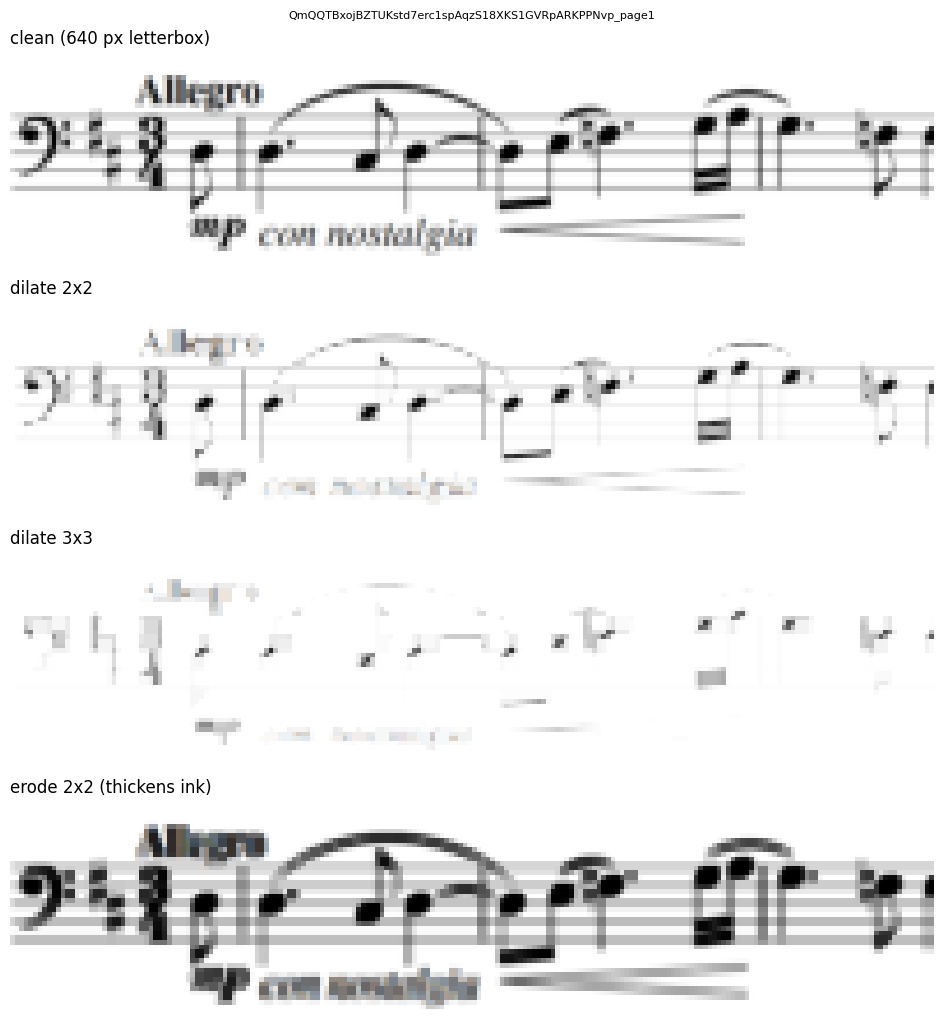

In [2]:
# The page with the most stems among the sample, cropped at the start of its first staff
stem = max(pages[:20], key=lambda s: sum(c.startswith("stem") for c in load(s)[2]))
canvas, boxes, classes = load(stem)
staff = next(b for b, c in zip(boxes, classes) if c == "staff")
cx, cy, bw, bh = staff
x0, y0 = int(cx - bw / 2), int(cy - bh / 2) - 12
crop = (slice(y0, y0 + int(bh) + 24), slice(x0, x0 + 200))

panels = {"clean (640 px letterbox)": canvas, **{k: f(canvas) for k, f in OPS.items()}}
fig, axes = plt.subplots(len(panels), 1, figsize=(12, 2.6 * len(panels)))
for ax, (name, img) in zip(axes, panels.items()):
    ax.imshow(img[crop], interpolation="nearest")
    ax.set_title(name, loc="left")
    ax.set_axis_off()
fig.suptitle(stem, fontsize=8)
fig.tight_layout()

## 2. How much survives, over 60 validation-lite pages

**Contrast** = 255 − the darkest pixel inside a box. For stems and barlines only the middle half of the box counts, so the notehead or the staff at their ends does not; for staves, each row's median across columns is taken first, so symbols do not count and only the lines do.

A box counts as **erased** when its contrast falls below a quarter of its clean value.

In [3]:
def contrast(gray, box, cls):
    cx, cy, bw, bh = box
    x1, x2, y1, y2 = cx - bw / 2, cx + bw / 2, cy - bh / 2, cy + bh / 2
    if cls.startswith(("stem", "barline")):
        y1, y2 = y1 + bh / 4, y2 - bh / 4
    xa, xb = int(np.floor(x1)), int(np.ceil(x2))
    ya, yb = int(np.floor(y1)), int(np.ceil(y2))
    win = gray[max(ya, 0) : max(yb, ya + 1), max(xa, 0) : max(xb, xa + 1)]
    if win.size == 0:
        return None
    if cls == "staff":
        return 255 - float(np.median(win, axis=1).min())
    return 255 - float(win.min())


CLASSES = ["stem4", "stem8", "barlineSingle", "staff", "noteheadBlack", "beam8"]
clean = {c: [] for c in CLASSES}
augmented = {k: {c: [] for c in CLASSES} for k in OPS}
for stem in pages:
    canvas, boxes, classes = load(stem)
    gray = canvas.mean(axis=2)
    outs = {k: f(canvas).mean(axis=2) for k, f in OPS.items()}
    for box, cls in zip(boxes, classes):
        if cls not in clean:
            continue
        c0 = contrast(gray, box, cls)
        if c0 is None or c0 < 10:
            continue
        clean[cls].append(c0)
        for k in OPS:
            augmented[k][cls].append(contrast(outs[k], box, cls))

rows = []
for cls in CLASSES:
    c0 = np.array(clean[cls])
    row = {"class": cls, "boxes": len(c0), "clean contrast": round(c0.mean())}
    for k in OPS:
        a = np.array(augmented[k][cls])
        row[f"{k}: contrast"] = round(a.mean())
        row[f"{k}: erased %"] = round(100 * np.mean(a < 0.25 * c0), 1)
    rows.append(row)
pd.DataFrame(rows).set_index("class")

,boxes,clean contrast,dilate 2x2: contrast,dilate 2x2: erased %,dilate 3x3: contrast,dilate 3x3: erased %,erode 2x2 (thickens ink): contrast,erode 2x2 (thickens ink): erased %
class,,,,,,,,
stem4,1453,116,45,28.7,7,92.8,119,0.0
stem8,4005,116,43,28.1,8,92.2,123,0.0
barlineSingle,1144,137,61,18.1,4,98.7,137,0.0
staff,1299,78,38,2.7,6,96.1,99,0.0
noteheadBlack,5957,255,253,0.0,188,0.0,255,0.0
beam8,1134,255,254,0.0,203,0.0,255,0.0


## Conclusion

- **3×3 dilation wipes almost everything but the noteheads.** About 92% of stems, 99% of barlines and 96% of staff lines fall below a quarter of their contrast. In the crop the slurs, text, clef and time signature go too, and noteheads shrink to dots. The pipeline picks this kernel for 20% of training samples (p=0.4, then half of those), and every box stays in the targets.
- **2×2 dilation** (another 20% of samples) erases 28–29% of stems and 18% of barlines outright, and roughly halves the contrast of the rest.
- The damage lands on stems, barlines and staff lines, the same thin classes that are weak in the detector and collapse in the joint runs.
- `cv2.erode` is the operation that thickens dark ink.

**Recommendation:** drop the `cv2.dilate` step. Ink thickening belongs in the new augmentation module (musicset stage 2), where it can run at full resolution before downscaling.